In [1]:
import numpy as np
import pandas as pd
from matplotlib.pyplot import subplots
import statsmodels.api as sm
from statsmodels.stats.outliers_influence \
 import variance_inflation_factor as VIF
from statsmodels.stats.anova import anova_lm
from ISLP import load_data
from ISLP.models import (ModelSpec as MS,
 summarize,
 poly)

In [4]:
Auto = load_data("Auto")
Auto.columns
Auto.shape[0]

392

In [5]:
X = pd.DataFrame({'intercept': np.ones(Auto.shape[0]),
 'horsepower': Auto['horsepower']})

In [15]:
y = Auto['mpg']
model = sm.OLS(y, X)
results = model.fit()

In [10]:
design = MS(['horsepower'])
design = design.fit(Auto)
X = design.transform(Auto)

In [12]:
design = MS(['horsepower'])
X = design.fit_transform(Auto)
X[:3]

,intercept,horsepower
name,,
chevrolet chevelle malibu,1.0,130
buick skylark 320,1.0,165
plymouth satellite,1.0,150


In [22]:
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    mpg   R-squared:                       0.606
Model:                            OLS   Adj. R-squared:                  0.605
Method:                 Least Squares   F-statistic:                     599.7
Date:                Sat, 05 Jul 2025   Prob (F-statistic):           7.03e-81
Time:                        21:47:34   Log-Likelihood:                -1178.7
No. Observations:                 392   AIC:                             2361.
Df Residuals:                     390   BIC:                             2369.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
intercept     39.9359      0.717     55.660      0.000      38.525      41.347
horsepower    -0.1578      0.006    -24.489      0.000      -0.171      -0.145
==============================================================================
Omnibus:                       16.432   Durbin-Watson:                   0.920
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               17.305
Skew:                           0.492   Prob(JB):                     0.000175
Kurtosis:                       3.299   Cond. No.                         322.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [16]:
# Relationship since p is 0 and confidence interval never crosses 0. t value is relatively large indicating a strong relationship. Negative

In [17]:
# Add a line with slope m and intercept b to ax
def abline(ax, b, m, *args, **kwargs):
    xlim = ax.get_xlim()
    ylim = [m * xlim[0] + b, m * xlim[1] + b]
    ax.plot(xlim, ylim, *args, **kwargs)

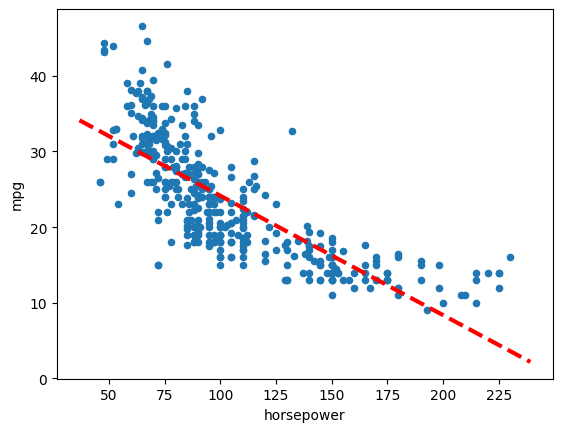

In [23]:
ax = Auto.plot.scatter('horsepower', 'mpg')
abline(ax, results.params.iloc[0], results.params.iloc[1], 'r--', linewidth=3)

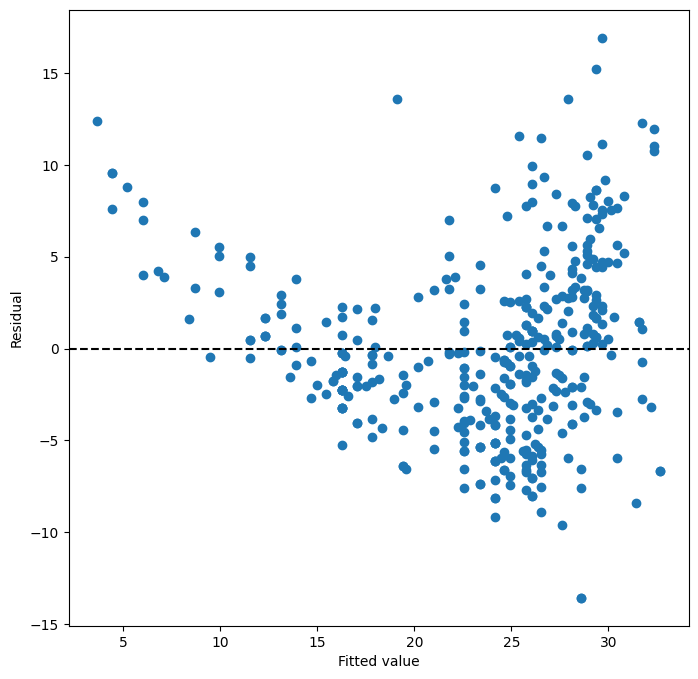

In [24]:
ax = subplots(figsize=(8,8))[1]
ax.scatter(results.fittedvalues, results.resid)
ax.set_xlabel('Fitted value')
ax.set_ylabel('Residual')
ax.axhline(0, c='k', ls='--');

115

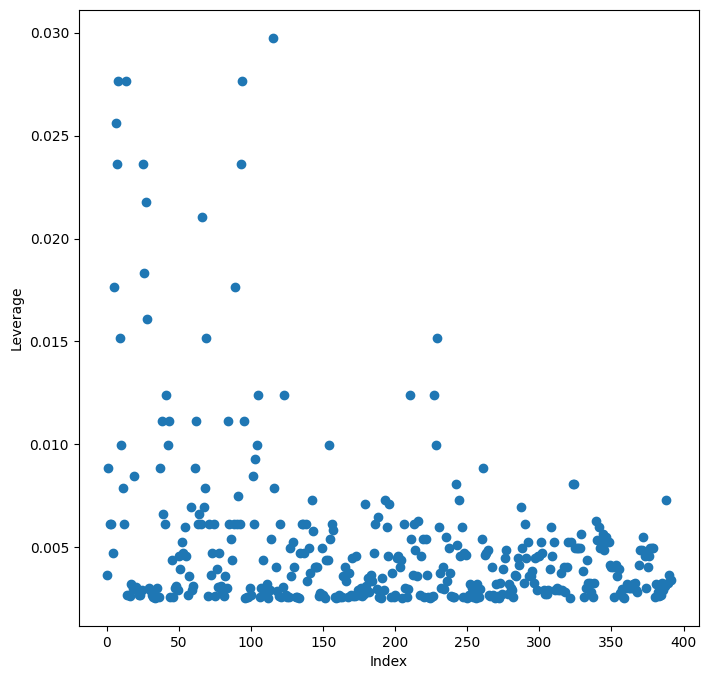

In [25]:
infl = results.get_influence()
ax = subplots(figsize=(8,8))[1]
ax.scatter(np.arange(X.shape[0]), infl.hat_matrix_diag)
ax.set_xlabel('Index')
ax.set_ylabel('Leverage')
np.argmax(infl.hat_matrix_diag)

In [27]:
X = MS([poly('horsepower', degree=2), 'mpg']).fit_transform(Auto)
model3 = sm.OLS(y, X)
results3 = model3.fit()
summarize(results3)

,coef,std err,t,P>|t|
intercept,1.998000e-15,3.630000e-15,5.500000e-01,0.582
"poly(horsepower, degree=2)[0]",9.237000e-14,2.250000e-14,4.103000e+00,0.000
"poly(horsepower, degree=2)[1]",-5.951000e-14,1.470000e-14,-4.035000e+00,0.000
mpg,1.000000e+00,1.520000e-16,6.570000e+15,0.000


In [29]:
anova_lm(results, results3)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,390.0,9.385916e+03,0.0,NaN,NaN,NaN
1,388.0,6.691434e-26,2.0,9385.915872,2.721192e+31,0.0
